In [13]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [14]:
heads = np.array([5, 8, 4, 7, 9])

total_tosses = 10

tails = total_tosses - heads

print("Heads:", heads)
print("Tails:", tails)

Heads: [5 8 4 7 9]
Tails: [5 2 6 3 1]


In [15]:
# Initial probability of heads
theta_A = 0.60
theta_B = 0.50

# Initial mixing probabilities
pi_A = 0.50
pi_B = 0.50

# Number of iterations
max_iter = 10

print("Initial Parameters:")
print("Theta A:", theta_A)
print("Theta B:", theta_B)
print("Pi A:", pi_A)
print("Pi B:", pi_B)

Initial Parameters:
Theta A: 0.6
Theta B: 0.5
Pi A: 0.5
Pi B: 0.5


In [16]:
def binomial_probability(h, n, theta):

    return (
        math.comb(n, h)
        * (theta ** h)
        * ((1 - theta) ** (n - h))
    )

In [17]:
def E_step(heads, theta_A, theta_B, pi_A, pi_B):

    responsibilities_A = []

    for h in heads:

        # Probability of observation given Coin A
        p_A = binomial_probability(h, 10, theta_A)

        # Probability of observation given Coin B
        p_B = binomial_probability(h, 10, theta_B)

        # Bayes theorem
        numerator = pi_A * p_A

        denominator = (
            pi_A * p_A +
            pi_B * p_B
        )

        gamma_A = numerator / denominator

        responsibilities_A.append(gamma_A)

    responsibilities_A = np.array(responsibilities_A)

    responsibilities_B = 1 - responsibilities_A

    return responsibilities_A, responsibilities_B

In [18]:
def M_step(heads, tails, gamma_A, gamma_B):

    # Effective observations for Coin A
    weighted_heads_A = np.sum(gamma_A * heads)
    weighted_tosses_A = np.sum(gamma_A * (heads + tails))

    # Effective observations for Coin B
    weighted_heads_B = np.sum(gamma_B * heads)
    weighted_tosses_B = np.sum(gamma_B * (heads + tails))

    # Update coin probabilities
    new_theta_A = weighted_heads_A / weighted_tosses_A

    new_theta_B = weighted_heads_B / weighted_tosses_B

    # Update mixing probabilities
    new_pi_A = np.mean(gamma_A)
    new_pi_B = np.mean(gamma_B)

    return new_theta_A, new_theta_B, new_pi_A, new_pi_B

In [19]:
def calculate_log_likelihood(
    heads, theta_A, theta_B, pi_A, pi_B
):

    log_likelihood = 0

    for h in heads:

        p_A = binomial_probability(h, 10, theta_A)

        p_B = binomial_probability(h, 10, theta_B)

        probability = (
            pi_A * p_A +
            pi_B * p_B
        )

        log_likelihood += math.log(probability)

    return log_likelihood

In [20]:
# Store results
log_likelihood_history = []

theta_A_history = []
theta_B_history = []

print("EM ALGORITHM STARTED")
print("-" * 75)

for iteration in range(max_iter):

    # E-step
    gamma_A, gamma_B = E_step(
        heads,
        theta_A,
        theta_B,
        pi_A,
        pi_B
    )

    # Calculate log likelihood
    ll = calculate_log_likelihood(
        heads,
        theta_A,
        theta_B,
        pi_A,
        pi_B
    )

    # Save current values
    log_likelihood_history.append(ll)

    theta_A_history.append(theta_A)
    theta_B_history.append(theta_B)

    # M-step
    theta_A, theta_B, pi_A, pi_B = M_step(
        heads,
        tails,
        gamma_A,
        gamma_B
    )

    print(
        f"Iteration {iteration + 1:2d} | "
        f"Theta A: {theta_A:.4f} | "
        f"Theta B: {theta_B:.4f} | "
        f"Log Likelihood: {ll:.6f}"
    )

print("-" * 75)
print("EM ALGORITHM COMPLETED")

EM ALGORITHM STARTED
---------------------------------------------------------------------------
Iteration  1 | Theta A: 0.7130 | Theta B: 0.5813 | Log Likelihood: -11.320587
Iteration  2 | Theta A: 0.7327 | Theta B: 0.5549 | Log Likelihood: -10.077380
Iteration  3 | Theta A: 0.7522 | Theta B: 0.5316 | Log Likelihood: -9.961989
Iteration  4 | Theta A: 0.7674 | Theta B: 0.5162 | Log Likelihood: -9.869039
Iteration  5 | Theta A: 0.7771 | Theta B: 0.5087 | Log Likelihood: -9.822046
Iteration  6 | Theta A: 0.7827 | Theta B: 0.5063 | Log Likelihood: -9.805471
Iteration  7 | Theta A: 0.7858 | Theta B: 0.5062 | Log Likelihood: -9.800228
Iteration  8 | Theta A: 0.7878 | Theta B: 0.5070 | Log Likelihood: -9.798228
Iteration  9 | Theta A: 0.7890 | Theta B: 0.5079 | Log Likelihood: -9.797212
Iteration 10 | Theta A: 0.7899 | Theta B: 0.5089 | Log Likelihood: -9.796599
---------------------------------------------------------------------------
EM ALGORITHM COMPLETED


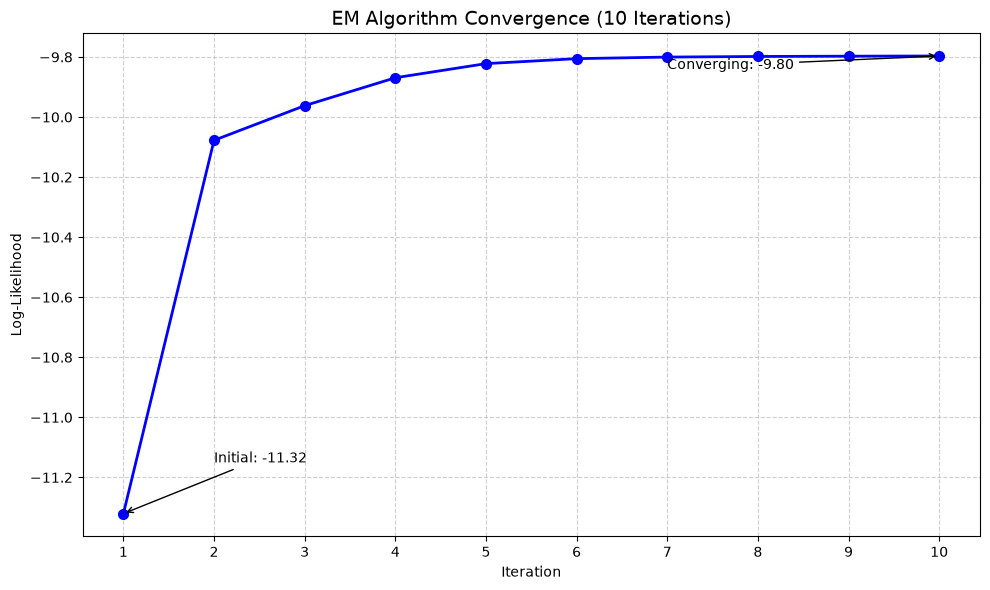

In [21]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 11),
    log_likelihood_history,
    marker='o',
    color='blue',
    linewidth=2,
    markersize=7
)

plt.title(
    "EM Algorithm Convergence (10 Iterations)",
    fontsize=14
)

plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")

plt.xticks(range(1, 11))

plt.grid(True, linestyle='--', alpha=0.6)

plt.annotate(
    "Initial: -11.32",
    xy=(1, log_likelihood_history[0]),
    xytext=(2, -11.15),
    arrowprops=dict(arrowstyle="->")
)

plt.annotate(
    "Converging: -9.80",
    xy=(10, log_likelihood_history[-1]),
    xytext=(7, -9.84),
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()
plt.show()

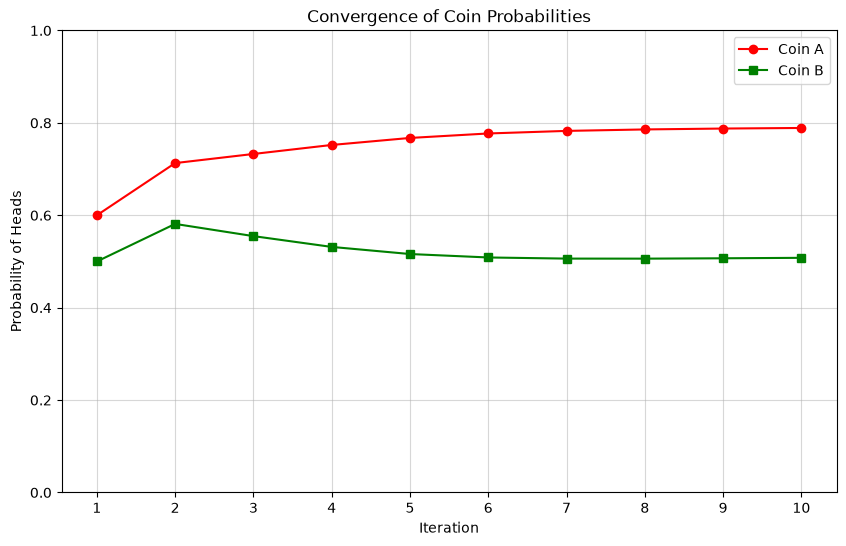

In [22]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 11),
    theta_A_history,
    marker='o',
    label='Coin A',
    color='red'
)

plt.plot(
    range(1, 11),
    theta_B_history,
    marker='s',
    label='Coin B',
    color='green'
)

plt.title("Convergence of Coin Probabilities")

plt.xlabel("Iteration")
plt.ylabel("Probability of Heads")

plt.xticks(range(1, 11))

plt.ylim(0, 1)

plt.legend()
plt.grid(True, alpha=0.5)

plt.show()